# Paris Air Quality Forecasting

Forecast the hourly concentration of five pollutants in Paris for the next **504 hours (3 weeks)**, comparing simple baselines, a **zero-shot foundation model (Chronos-2)** and an **LSTM**.

**Sections:** 0 Setup · 1 Data · 2 Validation and baselines · 3 Foundation models · 4 Zero-shot experiment · 5 Comparisons · 6 Results · 7 Final forecast.

**External information:** only calendar data known in advance (hour, weekday, French public holidays, Paris school holidays). No pollutant or weather value from the validation or test period is used.

## 0. Setup

**Google Colab:** *Runtime > Change runtime type > T4 GPU*, set `REPO` below to your (public) repository, then *Run all*: the notebook clones the repository to get the `data` folder. With a private repository, upload the `data` folder with the Files panel instead.

In [ ]:
%pip install -q chronos-forecasting holidays

In [2]:
import sys
from pathlib import Path

REPO = "https://github.com/ALX-7777/Time-series.git"     # Colab only: a notebook opened from GitHub comes without the data
FOLDERS = ["data", "../data", "final-project/data", "repo/data", "repo/final-project/data"]
if "google.colab" in sys.modules and not any(Path(f, "train.csv").exists() for f in FOLDERS):
    !git clone -q {REPO} repo

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

DATA = next((Path(f) for f in FOLDERS if Path(f, "train.csv").exists()), None)   # works locally and in Colab
assert DATA is not None, "data not found: set REPO (Colab) or open the notebook inside the project"
H = 504               # forecast horizon: 21 days x 24 hours
SEED = 0
plt.rcParams["figure.figsize"] = (12, 3.5)

## 1. Data understanding and preparation

**Q1. Load the data.** Identify the timestamp column and the five pollutant columns. Check that the dates are sorted and that there are no unexpected duplicates.

In [4]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print("train", train.shape, "| test", test.shape, "| sample submission", sample.shape)
train.head()

train (40991, 6) | test (504, 1) | sample submission (504, 6)


,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
0,2020-01-01 00,42.9,0.718,15.7,73.1,64.4
1,2020-01-01 01,33.6,0.587,10.1,74.8,66.0
2,2020-01-01 02,29.3,NaN,5.1,51.0,44.9
3,2020-01-01 03,30.5,0.246,7.2,27.7,25.1
4,2020-01-01 04,29.3,0.204,8.3,15.3,13.6


In [5]:
POLS = [c for c in train.columns if c.startswith("valeur_")]           # the five pollutants = the targets
train["timestamp"] = pd.to_datetime(train["id"], format="%Y-%m-%d %H")   # 'id' holds the date and hour, e.g. "2020-01-01 00"
test["timestamp"] = pd.to_datetime(test["id"], format="%Y-%m-%d %H")
df = train.set_index("timestamp")[POLS]

grid = pd.date_range(df.index.min(), df.index.max(), freq="h")           # the complete hourly grid
print("pollutants:", POLS)
print("train:", df.index.min(), "->", df.index.max(), "|", len(df), "hours")
print("test: ", test["timestamp"].min(), "->", test["timestamp"].max(), "|", len(test), "hours")
print("sorted:", df.index.is_monotonic_increasing, "| duplicated timestamps:", df.index.duplicated().sum(),
      "| hours missing from the grid:", len(grid.difference(df.index)))
print("test starts 1 hour after the end of train:", test["timestamp"].min() - df.index.max() == pd.Timedelta("1h"))
print("test ids = sample submission ids, same order:", test["id"].equals(sample["id"]))

pollutants: ['valeur_NO2', 'valeur_CO', 'valeur_O3', 'valeur_PM10', 'valeur_PM25']
train: 2020-01-01 00:00:00 -> 2024-09-03 22:00:00 | 40991 hours
test:  2024-09-03 23:00:00 -> 2024-09-24 22:00:00 | 504 hours
sorted: True | duplicated timestamps: 0 | hours missing from the grid: 0
test starts 1 hour after the end of train: True
test ids = sample submission ids, same order: True


Timestamp: `id` (`"YYYY-MM-DD HH"`, in CET). Targets: `valeur_NO2`, `valeur_CO` (mg/m³), `valeur_O3`, `valeur_PM10`, `valeur_PM25` (µg/m³). Train is a sorted hourly grid from 2020-01-01 to 2024-09-03 22h, with no duplicate and no missing timestamp. The test is the next 504 hours, in the order of the sample submission.

**Q2. Why is this a time-series forecasting problem, not a standard regression problem?**

- The rows are ordered and dependent: each hour depends on the previous hours (NO2 autocorrelation 0.92 at lag 1) and on the same hour of past days and weeks.
- There are no explanatory variables for the future: we extrapolate the series from a forecast origin.
- The output is a 504-hour trajectory whose error grows with the horizon, and the series is not stationary (seasonality, episodes, holidays).

**Q3. Why would a random train-test split create a misleading evaluation?**

- **Leakage:** each validation hour would have training hours just before and after it, so the model would interpolate instead of forecast, and the score would be far too optimistic.
- **Wrong task:** it would never measure errors 1 to 3 weeks ahead, which is what we must forecast.

So the split is **by date**: everything used for training comes before the validation period.

**Q4. Data quality: time range, missing values, duplicates, outliers and simple statistics.**

In [6]:
summary = df.describe().T.round(2)
summary["missing %"] = (100 * df.isna().mean()).round(1)
summary

,count,mean,std,min,25%,50%,75%,max,missing %
valeur_NO2,37694.0,21.83,14.66,1.10,11.30,17.60,28.20,131.00,8.0
valeur_CO,28462.0,0.20,0.10,0.04,0.14,0.18,0.23,4.31,30.6
valeur_O3,40298.0,50.57,26.49,-1.90,33.00,50.70,66.60,193.10,1.7
valeur_PM10,33824.0,18.22,11.28,0.50,10.70,15.60,22.90,128.50,17.5
valeur_PM25,39200.0,11.05,8.15,0.00,5.80,8.70,13.60,111.10,4.4


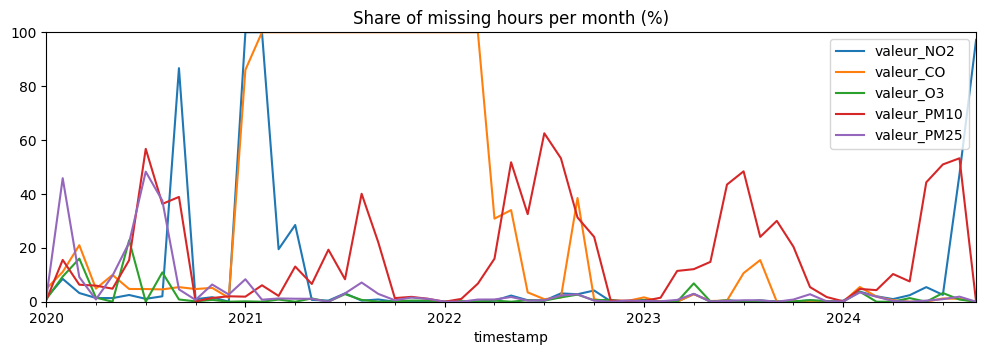

In [7]:
(100 * df.isna().resample("MS").mean()).plot(title="Share of missing hours per month (%)", ylim=(0, 100))
plt.show()

In [8]:
def gaps(s):
    """Blocks of consecutive missing hours of a series: start and length."""
    na = s.isna()
    block = na.ne(na.shift()).cumsum()            # a new id each time the series switches between value and NaN
    return s.index.to_series()[na].groupby(block[na]).agg(["min", "count"]).set_axis(["start", "hours"], axis=1)

rows = {}
for p in POLS:
    g = gaps(df[p])
    longest = g.loc[g["hours"].idxmax()]
    rows[p] = {"missing hours": df[p].isna().sum(), "gaps": len(g), "longest gap (h)": longest["hours"],
               "longest gap starts": longest["start"], "last observed hour": df[p].last_valid_index()}
pd.DataFrame(rows).T

,missing hours,gaps,longest gap (h),longest gap starts,last observed hour
valeur_NO2,3297,161,1500,2021-01-01 00:00:00,2024-09-01 01:00:00
valeur_CO,12529,411,10949,2021-01-05 09:00:00,2024-09-03 22:00:00
valeur_O3,693,71,131,2020-06-02 19:00:00,2024-09-03 22:00:00
valeur_PM10,7167,749,90,2022-07-13 06:00:00,2024-09-03 22:00:00
valeur_PM25,1791,209,493,2020-07-23 00:00:00,2024-09-03 22:00:00


In [9]:
for p in POLS:
    s = df[p]
    q1, q3 = s.quantile([0.25, 0.75])
    high = q3 + 3 * (q3 - q1)                       # far-out values: Tukey fence with 3 IQR
    print(f"{p:12s} min {s.min():6.2f} | {100 * (s > high).mean():.1f}% of hours above {high:6.2f} | max {s.max():6.1f} on {s.idxmax()}")

valeur_NO2   min   1.10 | 0.5% of hours above  78.90 | max  131.0 on 2023-09-07 22:00:00
valeur_CO    min   0.04 | 1.4% of hours above   0.47 | max    4.3 on 2022-05-17 08:00:00
valeur_O3    min  -1.90 | 0.0% of hours above 167.40 | max  193.1 on 2020-08-11 12:00:00
valeur_PM10  min   0.50 | 0.8% of hours above  59.50 | max  128.5 on 2022-01-15 14:00:00
valeur_PM25  min   0.00 | 1.6% of hours above  37.00 | max  111.1 on 2022-01-15 14:00:00


- **Range:** 40,991 hours, no duplicate, no missing timestamp.
- **Missing values:** CO 31% (almost all of 2021), PM10 17% (many short daytime gaps), NO2 8%, including the **last 69 hours before the test**. O3 and PM2.5 are almost complete.
- **Outliers:** the high values are real episodes (particles on 15 January 2022, New Year fireworks, heat wave of 7–8 September 2023), so they are kept. A few slightly negative O3 values are sensor noise: forecasts are clipped at 0.
- **Scales:** NO2 ≈ 22, O3 ≈ 51, PM10 ≈ 18, PM2.5 ≈ 11 µg/m³, CO ≈ 0.2 mg/m³.

**Q5. Plot the pollutant series and describe trends, daily or weekly patterns, peaks and relationships between pollutants.**

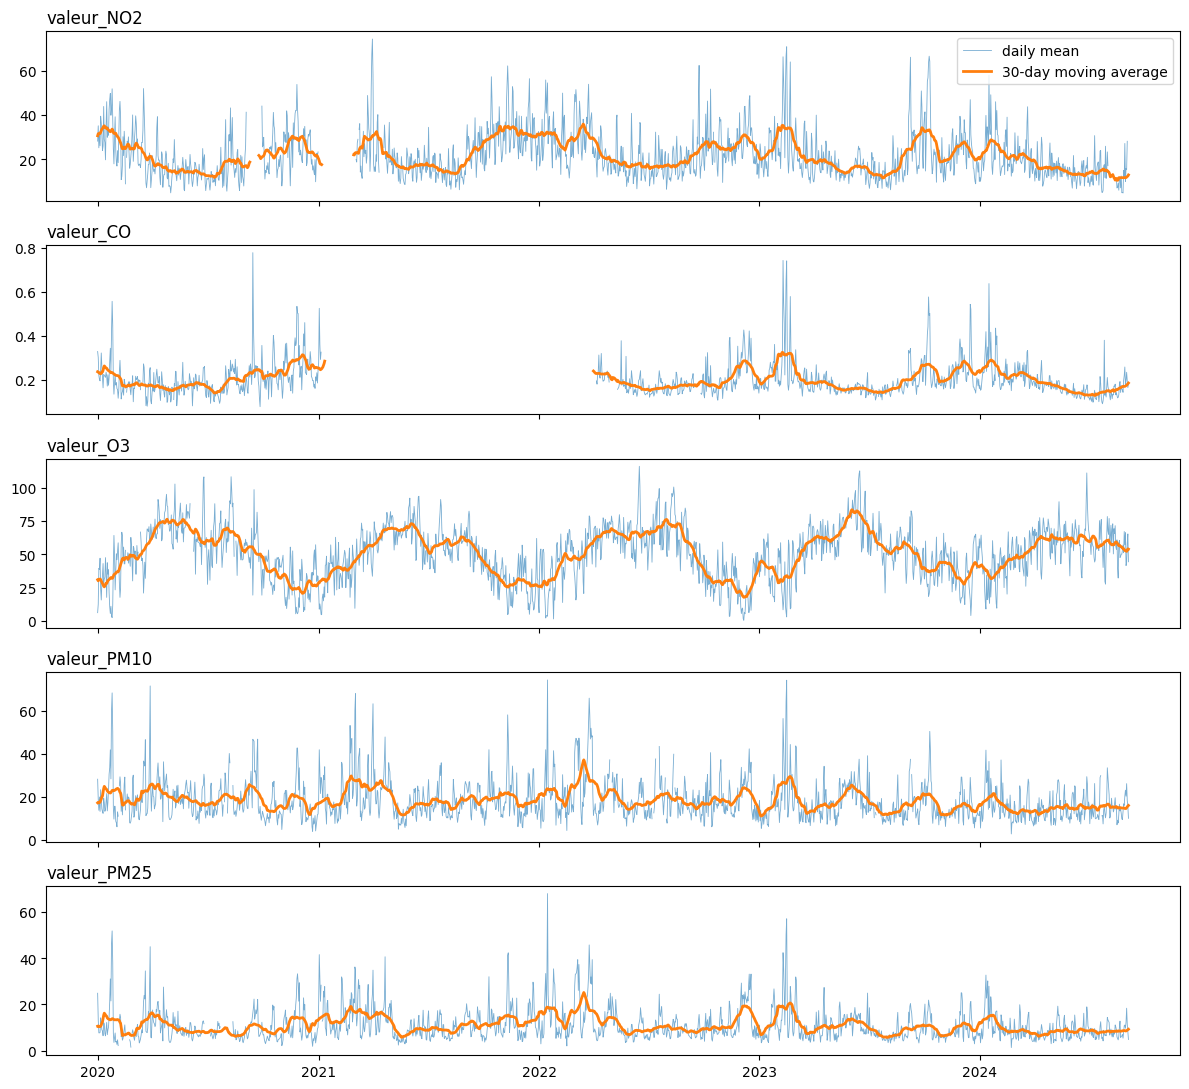

In [10]:
daily = df.resample("D").mean()
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for ax, p in zip(axes, POLS):
    ax.plot(daily[p], lw=0.6, alpha=0.6, label="daily mean")
    ax.plot(daily[p].rolling(30, center=True, min_periods=10).mean(), lw=2, label="30-day moving average")
    ax.set_title(p, loc="left")
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

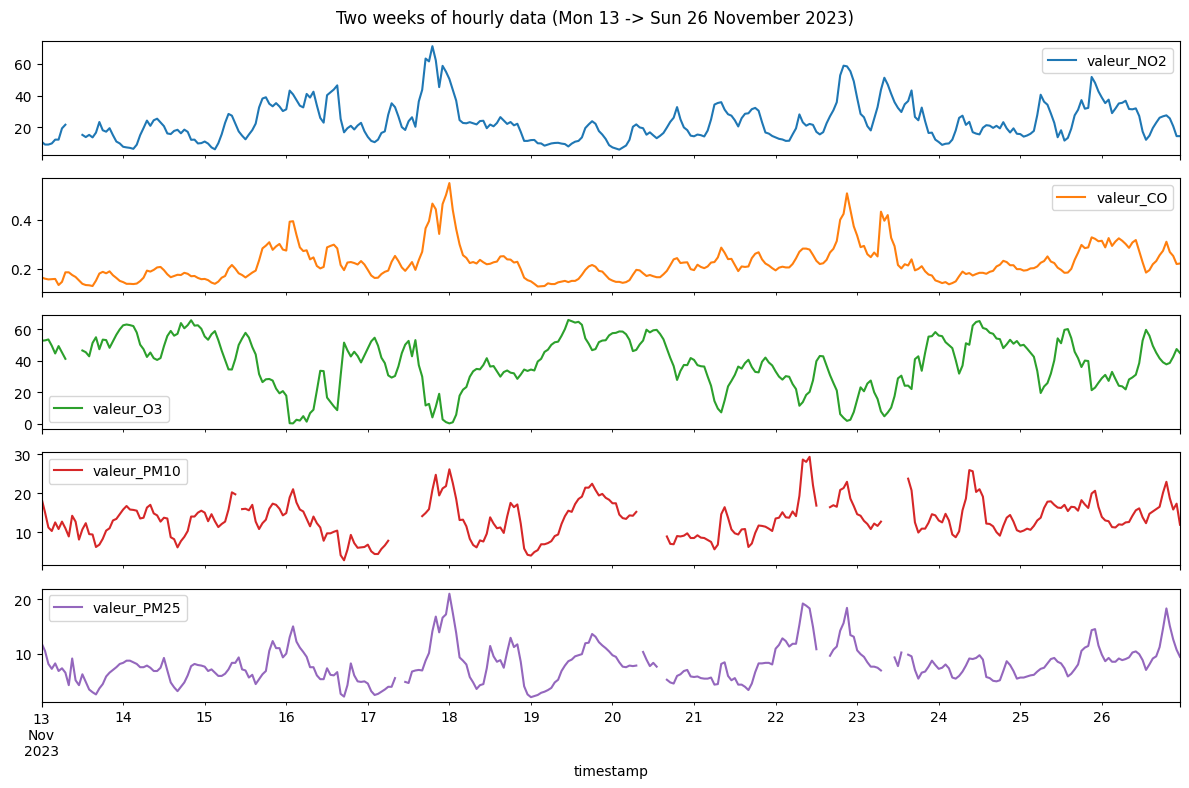

In [11]:
two_weeks = df.loc["2023-11-13":"2023-11-26"]     # Monday 13 -> Sunday 26 November 2023, hourly values
two_weeks.plot(subplots=True, figsize=(12, 8), title="Two weeks of hourly data (Mon 13 -> Sun 26 November 2023)")
plt.tight_layout(); plt.show()

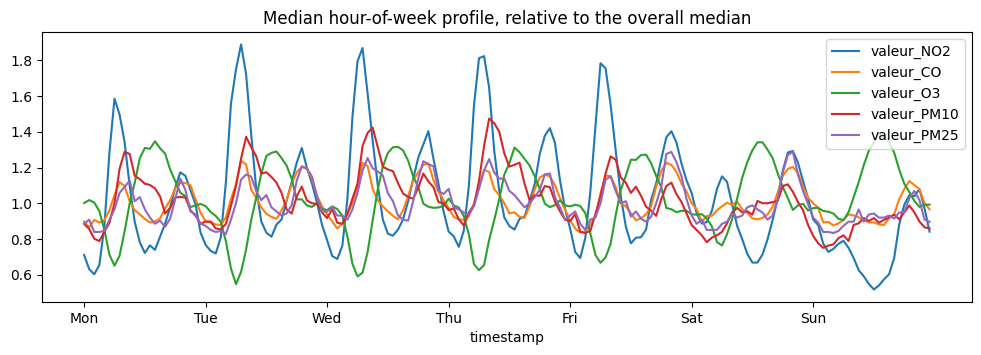

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
valeur_NO2,20.62,23.53,23.96,24.32,23.50,20.21,16.63
valeur_CO,0.19,0.21,0.21,0.21,0.20,0.20,0.19
valeur_O3,50.65,49.22,49.37,49.93,49.84,51.53,53.46
valeur_PM10,17.64,19.07,19.99,19.55,18.50,17.33,15.50
valeur_PM25,10.37,11.18,11.85,11.41,11.06,11.18,10.33


In [12]:
hour_of_week = df.index.dayofweek * 24 + df.index.hour          # 0 = Monday 00h ... 167 = Sunday 23h
ax = (df.groupby(hour_of_week).median() / df.median()).plot(title="Median hour-of-week profile, relative to the overall median")
ax.set_xticks(range(0, 168, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.show()
by_day = df.groupby(df.index.dayofweek).mean().round(2)
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day.T

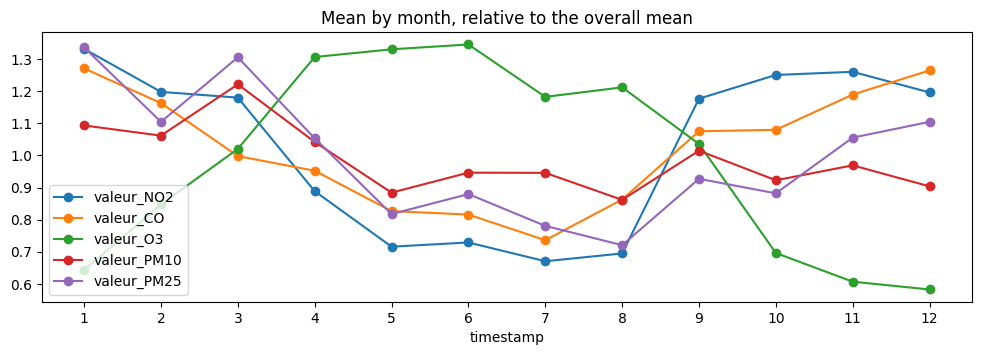

timestamp,NO2 August,NO2 September
timestamp,,
2020,18.0,28.8
2021,13.5,25.0
2022,16.9,22.6
2023,14.8,28.9
2024,10.5,NaN


In [13]:
ax = (df.groupby(df.index.month).mean() / df.mean()).plot(marker="o", title="Mean by month, relative to the overall mean")
ax.set_xticks(range(1, 13))
plt.show()
aug_sep = df.loc[df.index.month.isin([8, 9]) & (df.index < "2024-09-01"), "valeur_NO2"]
aug_sep.groupby([aug_sep.index.year, aug_sep.index.month]).mean().unstack().round(1).rename(columns={8: "NO2 August", 9: "NO2 September"})

In [14]:
df.corr().round(2).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
valeur_NO2,1.000000,0.710000,-0.640000,0.510000,0.520000
valeur_CO,0.710000,1.000000,-0.480000,0.530000,0.630000
valeur_O3,-0.640000,-0.480000,1.000000,-0.210000,-0.300000
valeur_PM10,0.510000,0.530000,-0.210000,1.000000,0.890000
valeur_PM25,0.520000,0.630000,-0.300000,0.890000,1.000000


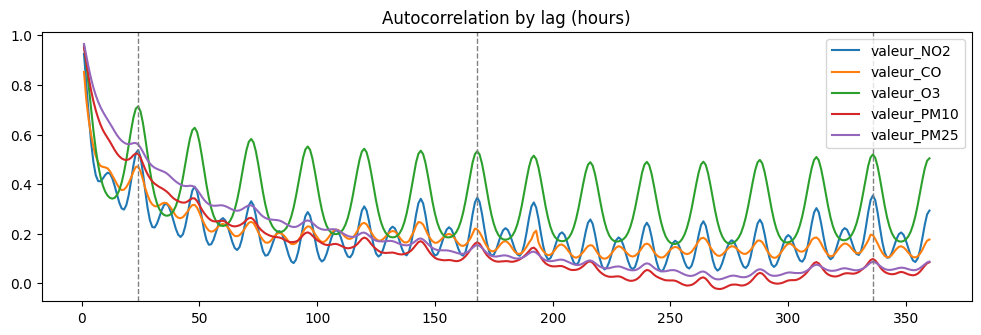

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
1,0.92,0.85,0.96,0.95,0.96
12,0.44,0.45,0.34,0.57,0.65
24,0.54,0.47,0.71,0.52,0.56
144,0.34,0.25,0.53,0.17,0.18
168,0.35,0.22,0.53,0.17,0.15
336,0.35,0.19,0.52,0.10,0.09


In [15]:
lags = range(1, 24 * 15 + 1)                                       # up to 15 days
acf = pd.DataFrame({p: [df[p].autocorr(k) for k in lags] for p in POLS}, index=lags)   # corr(y_t, y_t-k), missing pairs ignored
ax = acf.plot(title="Autocorrelation by lag (hours)")
for k in (24, 168, 336):
    ax.axvline(k, color="grey", ls="--", lw=1)
plt.show()
acf.loc[[1, 12, 24, 144, 168, 336]].round(2)

**Q6. Which patterns are visible in the data: hourly, daily or weekly? Evidence from the plots.**

- **Daily cycle, the strongest:** NO2 peaks at rush hours, and O3 does the opposite (destroyed by traffic NO in the morning, produced by sunlight in the afternoon). The autocorrelation peaks every 24 hours.
- **Weekly cycle:** NO2 is about 30% lower on Sundays and loses its morning peak; its autocorrelation has local maxima at 168 and 336 hours.
- **Yearly cycle:** NO2, CO and PM2.5 are higher in winter, O3 in summer. NO2 drops in August and **jumps in September** (+35% to +95%), which matters because the test covers 3–24 September.
- **Links:** PM10–PM2.5 0.89, NO2–CO 0.71, NO2–O3 −0.64, an argument for forecasting the pollutants jointly.
- **Clock:** timestamps are in CET all year (no summer time), so the traffic peaks appear one hour earlier in summer.

**Q7. How will you handle missing values? Why must you not interpolate using future validation or test data?**

- No row is deleted (the hourly grid stays regular), and the MAE is computed on observed hours only.
- Chronos-2 receives the missing values as they are and masks them. The baselines use the same hour one season earlier. The LSTM replaces missing inputs by the mean and ignores missing targets in its loss.
- **No interpolation across the forecast origin:** it would use a value from the validation or test period, unknown at forecast time. Filling the NO2 gap before the test with a September value would leak the post-holiday level and make the validation over-optimistic. Means and scalers are also computed on past data only.

## 2. Validation strategy and baselines

Every model is evaluated on the same windows with the same metric: the MAE of each pollutant on the observed hours, and the average of the five MAEs (the competition score).

**Q8. Create a time-based validation split with a 504-hour forecast horizon.** Make sure no future information enters the training data.

In [16]:
def split(origin, hide_no2_hours=0):
    """Context = every hour before the forecast origin; truth = the next H hours."""
    origin = pd.Timestamp(origin)
    context = df.loc[: origin - pd.Timedelta("1h")].copy()
    truth = df.loc[origin : origin + pd.Timedelta(hours=H - 1)]
    if hide_no2_hours:                                   # mimic the test: NO2 unknown in the last hours of the context
        context.iloc[-hide_no2_hours:, POLS.index("valeur_NO2")] = np.nan
    assert context.index.max() < truth.index.min() and len(truth) == H     # no future hour in the context
    return context, truth

folds = {
    "val_2024": split(df.index[-H]),                             # official validation: the last 504 hours of train
    "sept_2023": split("2023-09-03 23:00", hide_no2_hours=69),   # test-like check: same calendar window as the test, one year earlier
}
for name, (context, truth) in folds.items():
    print(f"{name:9s} | context {context.index.min()} -> {context.index.max()} | validation {truth.index.min()} -> {truth.index.max()}")
    print(f"{'':9s} | observed hours in the validation window: {truth.notna().sum().to_dict()}")

val_2024  | context 2020-01-01 00:00:00 -> 2024-08-13 22:00:00 | validation 2024-08-13 23:00:00 -> 2024-09-03 22:00:00
          | observed hours in the validation window: {'valeur_NO2': 394, 'valeur_CO': 498, 'valeur_O3': 504, 'valeur_PM10': 299, 'valeur_PM25': 491}
sept_2023 | context 2020-01-01 00:00:00 -> 2023-09-03 22:00:00 | validation 2023-09-03 23:00:00 -> 2023-09-24 22:00:00
          | observed hours in the validation window: {'valeur_NO2': 503, 'valeur_CO': 504, 'valeur_O3': 504, 'valeur_PM10': 351, 'valeur_PM25': 504}


- **`val_2024`:** the last 504 hours of train (13 August → 3 September 2024), same length as the test and just before it. Models only see the hours before it, and the `assert` checks it.
- **`sept_2023`:** the same calendar window as the test, one year earlier, with NO2 hidden for the last 69 hours of the context as in the real test. It covers the *rentrée*, which `val_2024` (August holidays) does not contain.
- In `val_2024`, NO2 is observed on only 394 hours and PM10 on 299: their MAE uses these hours only.

**Q9. Implement at least two baselines: persistence and seasonal naive (168-hour lag).** We also add a 24-hour seasonal naive, the competition baseline (mean of the history) and the median of the last 4 weeks at the same hour of the week.

In [17]:
def persistence(context):
    """Naive forecast: repeat the last observed value of each pollutant."""
    return pd.DataFrame({p: np.repeat(context[p].dropna().iloc[-1], H) for p in POLS})

def seasonal_naive(context, season):
    """Repeat the last `season` hours. A missing value is taken from the same hour one more season earlier."""
    out = {}
    for p in POLS:
        last = context[p].iloc[-season:].to_numpy()
        k = 2
        while np.isnan(last).any() and k * season <= len(context):
            last = np.where(np.isnan(last), context[p].iloc[-k * season : -(k - 1) * season].to_numpy(), last)
            k += 1
        out[p] = np.resize(last, H)                     # repeat the season until H values
    return pd.DataFrame(out)

def mean_forecast(context):
    """Competition baseline: the mean of the whole history, for every hour."""
    return pd.DataFrame({p: np.repeat(context[p].mean(), H) for p in POLS})

def seasonal_median(context, weeks=4):
    """Median of the same hour of the week over the last 4 weeks: less noisy than a single week."""
    return pd.DataFrame({p: np.resize(np.nanmedian(context[p].iloc[-weeks * 168:].to_numpy().reshape(weeks, 168), axis=0), H)
                         for p in POLS})

def mae(truth, pred):
    """MAE of each pollutant on the observed hours, and the average of the 5 MAEs (the competition score)."""
    errors = (truth - pred.set_axis(truth.index).clip(lower=0)).abs().mean()     # missing true values are skipped
    return pd.concat([errors, pd.Series({"average": errors.mean()})])

In [18]:
baselines = {
    "mean (competition baseline)": mean_forecast,
    "persistence": persistence,
    "seasonal naive 24 h": lambda c: seasonal_naive(c, 24),
    "seasonal naive 168 h": lambda c: seasonal_naive(c, 168),
    "seasonal median 4 weeks": seasonal_median,
}
preds = {fold: {} for fold in folds}       # preds[fold][model] = the 504 x 5 forecasts, reused in sections 4 to 7
scores = {}
for fold, (context, truth) in folds.items():
    for name, forecast in baselines.items():
        preds[fold][name] = forecast(context)
        scores[(fold, name)] = mae(truth, preds[fold][name])
scores = pd.DataFrame(scores).T            # one row per (window, model): MAE of each pollutant + average
scores.round(3)

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  mean (competition baseline)      12.763      0.046     16.011   
          persistence                       7.429      0.046     16.160   
          seasonal naive 24 h              10.374      0.045     14.254   
          seasonal naive 168 h              9.469      0.044     17.303   
          seasonal median 4 weeks           8.614      0.046     14.889   
sept_2023 mean (competition baseline)      14.881      0.059     23.529   
          persistence                      21.253      0.060     23.521   
          seasonal naive 24 h              15.277      0.063     21.357   
          seasonal naive 168 h             17.073      0.064     25.345   
          seasonal median 4 weeks          16.416      0.064     20.888   

                                       valeur_PM10  valeur_PM25  average  
val_2024  mean (competition baseline)        6.141        4.442    7.881  
          persistence                        5.622        4.237    6.699  
          seasonal naive 24 h                6.676        4.210    7.112  
          seasonal naive 168 h               6.439        3.555    7.362  
          seasonal median 4 weeks            6.079        3.242    6.574  
sept_2023 mean (competition baseline)        7.429        5.172   10.214  
          persistence                        7.904        5.819   11.711  
          seasonal naive 24 h                7.931        5.582   10.042  
          seasonal naive 168 h               7.876        5.322   11.136  
          seasonal median 4 weeks            7.037        5.259    9.933

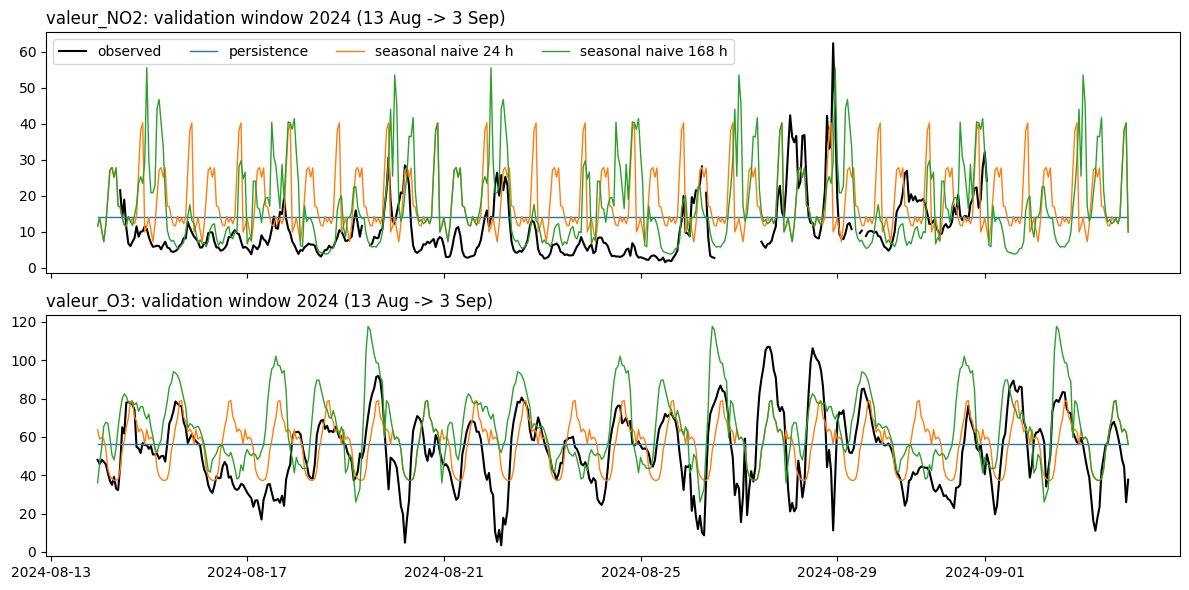

In [19]:
context, truth = folds["val_2024"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, p in zip(axes, ["valeur_NO2", "valeur_O3"]):
    ax.plot(truth[p], color="black", lw=1.5, label="observed")
    for name in ["persistence", "seasonal naive 24 h", "seasonal naive 168 h"]:
        ax.plot(truth.index, preds["val_2024"][name][p], lw=1, label=name)
    ax.set_title(f"{p}: validation window 2024 (13 Aug -> 3 Sep)", loc="left")
axes[0].legend(ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

**Comments.**
- `val_2024`: the best baseline is the 4-week median (6.57), then persistence (6.70). The mean of the history is the worst (7.88), because August is much cleaner than the yearly average.
- NO2 is missing for the 13 days before `val_2024`, so the seasonal naives copy late-July rush hours (peaks of 40) while August stays around 10.
- `sept_2023` is much harder for every baseline (9.9 to 11.7): NO2 jumps after the holidays and a heat wave adds an episode.

**Q10. Why is a 168-hour lag useful for hourly urban pollution data?**

- Human activity (traffic, work, school) repeats every week. Lag 168 compares each hour with the same hour of the same weekday, so it keeps both the daily shape and the weekday/weekend contrast; lag 24 forecasts a Sunday with a Saturday.
- Evidence: in `val_2024`, lag 168 beats lag 24 on NO2, PM10 and PM2.5.
- Limit: it copies the weather of a single week, so lag 24 is better for O3 (driven by the weather), and the 4-week median is more robust.

**Q11. Why should you report MAE for each pollutant, not only the average MAE?** The table gives the share of each pollutant in the average MAE.

In [20]:
share = scores.drop(columns="average")
(100 * share.div(share.sum(axis=1), axis=0)).round(1)     # % of the average MAE that comes from each pollutant

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  mean (competition baseline)        32.4        0.1       40.6   
          persistence                        22.2        0.1       48.2   
          seasonal naive 24 h                29.2        0.1       40.1   
          seasonal naive 168 h               25.7        0.1       47.0   
          seasonal median 4 weeks            26.2        0.1       45.3   
sept_2023 mean (competition baseline)        29.1        0.1       46.1   
          persistence                        36.3        0.1       40.2   
          seasonal naive 24 h                30.4        0.1       42.5   
          seasonal naive 168 h               30.7        0.1       45.5   
          seasonal median 4 weeks            33.1        0.1       42.1   

                                       valeur_PM10  valeur_PM25  
val_2024  mean (competition baseline)         15.6         11.3  
          persistence                         16.8         12.6  
          seasonal naive 24 h                 18.8         11.8  
          seasonal naive 168 h                17.5          9.7  
          seasonal median 4 weeks             18.5          9.9  
sept_2023 mean (competition baseline)         14.5         10.1  
          persistence                         13.5          9.9  
          seasonal naive 24 h                 15.8         11.1  
          seasonal naive 168 h                14.1          9.6  
          seasonal median 4 weeks             14.2         10.6

- **Different scales:** the raw average is dominated by O3 (40–48% of it) and NO2 (22–36%), while CO counts for 0.1%: a model could fail on CO without changing the average.
- **Opposite behaviours:** lag 168 beats lag 24 on four pollutants out of five, but loses on average only because of O3.
- **Diagnosis:** the per-pollutant errors show where to improve (NO2 at the *rentrée*), and each pollutant has its own health thresholds.

## 3. Time-series foundation models

We use **Chronos-2** (Ansari et al., 2025) in **zero-shot** mode.

**Q12. What is a time-series foundation model? How is it different from a model trained only on this dataset?**

A large neural network **pretrained once on a huge and diverse collection of time series** (over a million real series plus synthetic ones), then **reused as it is**: we give it the recent history (the *context*) and it returns the forecast, like a language model continuing a text. Chronos-2 is a 120 M-parameter Transformer that reads patches of 16 hours, shares information along time and across the series of a group (*group attention*), and outputs quantiles for up to 1,024 steps from up to 8,192 hours of context.

| | Foundation model (Chronos-2) | Model trained on this dataset (LSTM) |
|---|---|---|
| Learns from | many domains, before seeing our data | the Paris data only |
| Our data is | the input at prediction time | the training set |
| Strengths | no training, robust, handles missing values and covariates | can learn Paris-specific patterns |
| Weaknesses | knows Paris only through its 11-month context | needs data and tuning, risk of over-fitting |

**Q13. What does zero-shot forecasting mean in this context?**

Chronos-2 forecasts the Paris pollutants **without any training on them**: its weights stay frozen, and our data is only the input it reads at prediction time; it adapts *in context*, through attention. Zero-shot does not mean untrained: the model was trained, but on other data, and Paris is not in its training corpus.

**Q14. Why could forecasting all pollutants together help? Give one possible advantage and one possible risk.**

With Chronos-2, the five pollutants are put in one group, so each series can read the others.
- **Advantage:** the pollutants share their drivers (traffic, weather, chemistry). When one series has no recent values, like NO2 just before the test, the model can infer its level from CO and O3, observed until the end.
- **Risk:** wrong or unstable links are transferred too. The NO2–O3 correlation is −0.77 in winter but only −0.31 in summer (cell below), and an error or a gap in one series can hurt the others.

In [21]:
season = df.index.month.map({12: "winter", 1: "winter", 2: "winter", 6: "summer", 7: "summer", 8: "summer"})
df.groupby(season)[["valeur_NO2", "valeur_O3"]].corr().round(2)      # the NO2-O3 link depends on the season

valeur_NO2  valeur_O3
timestamp                                  
summer    valeur_NO2        1.00      -0.31
          valeur_O3        -0.31       1.00
winter    valeur_NO2        1.00      -0.77
          valeur_O3        -0.77       1.00

**Q15. Classify the following as target, past-only covariate or known-future covariate: pollutant history, historical weather, hour of day and future weather observations.**

| Variable | Role |
|---|---|
| Pollutant history | **Target**: its past is the context, its future is what we forecast |
| Historical weather | **Past-only covariate**: known up to the origin, unknown after it (not used here) |
| Hour of day | **Known-future covariate**: calendar information, known for every future hour (used) |
| Future weather observations | **Not usable**: unknown at forecast time, so using them is leakage (forbidden). A weather *forecast* made before the origin would be a known-future covariate |

## 4. Zero-shot forecasting experiment

Chronos-2 is run twice on each window: the five pollutants together (joint), then the same with calendar covariates.

**Q16. Run the foundation model in zero-shot mode. Record the model name, version, hardware and main settings.**

In [22]:
from importlib.metadata import version
from huggingface_hub import model_info
from chronos import Chronos2Pipeline

MODEL = "amazon/chronos-2"
device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = Chronos2Pipeline.from_pretrained(MODEL, device_map=device)     # pretrained weights, used as they are

pd.Series({
    "model": MODEL,
    "model revision (Hugging Face commit)": model_info(MODEL).sha[:12],
    "parameters": f"{sum(w.numel() for w in pipeline.model.parameters()) / 1e6:.1f} M",
    "chronos-forecasting version": version("chronos-forecasting"),
    "torch version": torch.__version__,
    "hardware": torch.cuda.get_device_name(0) if device == "cuda" else "CPU",
    "weights frozen (evaluation mode, no training)": not pipeline.model.training,
    "context length used (hours)": pipeline.model.chronos_config.context_length,
    "forecast horizon (hours)": H,
    "quantiles": "0.1, 0.5, 0.9 (point forecast = median)",
}, name="setup")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

model                                                                   amazon/chronos-2
model revision (Hugging Face commit)                                        29ec3766d36d
parameters                                                                       119.5 M
chronos-forecasting version                                                        2.3.2
torch version                                                                 2.10.0+cpu
hardware                                                                             CPU
weights frozen (evaluation mode, no training)                                       True
context length used (hours)                                                         8192
forecast horizon (hours)                                                             504
quantiles                                        0.1, 0.5, 0.9 (point forecast = median)
Name: setup, dtype: object

- The table records the model with its exact Hugging Face revision, the library versions and the hardware.
- **Zero-shot:** there is no training step anywhere; the weights stay frozen.
- **Settings:** the whole history as context (the model keeps the last 8,192 hours), 504 hours in one direct pass, quantiles 0.1 / 0.5 / 0.9 with the median as point forecast, default values otherwise. The forecasts are deterministic.

**Q17. Prepare the data in the format expected by the model.** Use only information available before the validation period. Calendar sources: French public holidays (`holidays` package) and the Paris school calendar (Ministry of Education open data).

In [23]:
import holidays

# Paris (zone C) school holidays for pupils: (first day off, day classes restart). Source: data.education.gouv.fr, "fr-en-calendrier-scolaire"
SCHOOL_HOLIDAYS = [("2019-10-19", "2019-11-04"), ("2019-12-21", "2020-01-06"), ("2020-02-08", "2020-02-24"), ("2020-04-04", "2020-04-20"),
                   ("2020-07-04", "2020-09-01"), ("2020-10-17", "2020-11-02"), ("2020-12-19", "2021-01-04"), ("2021-02-13", "2021-03-01"),
                   ("2021-04-10", "2021-04-26"), ("2021-07-06", "2021-09-02"), ("2021-10-23", "2021-11-08"), ("2021-12-18", "2022-01-03"),
                   ("2022-02-19", "2022-03-07"), ("2022-04-23", "2022-05-09"), ("2022-07-07", "2022-09-01"), ("2022-10-22", "2022-11-07"),
                   ("2022-12-17", "2023-01-03"), ("2023-02-18", "2023-03-06"), ("2023-04-22", "2023-05-09"), ("2023-07-08", "2023-09-04"),
                   ("2023-10-21", "2023-11-06"), ("2023-12-23", "2024-01-08"), ("2024-02-10", "2024-02-26"), ("2024-04-06", "2024-04-22"),
                   ("2024-07-06", "2024-09-02")]
PUBLIC_HOLIDAYS = pd.to_datetime(list(holidays.France(years=range(2019, 2025))))
CALENDAR = ["hour", "weekday", "day_off", "school_holiday"]

def calendar(timestamps):
    """Calendar information known in advance, for any timestamps (past or future)."""
    t = pd.DatetimeIndex(timestamps)
    day = t.normalize()
    school = np.zeros(len(t), dtype=int)
    for start, end in SCHOOL_HOLIDAYS:
        school[(day >= start) & (day < end)] = 1
    return pd.DataFrame({"hour": t.hour, "weekday": t.dayofweek,
                         "day_off": (day.isin(PUBLIC_HOLIDAYS) | (t.dayofweek == 6)).astype(int),   # Sunday or public holiday
                         "school_holiday": school}, index=t)

In [24]:
def chronos_inputs(context, covariates=(), joint=True):
    """Long-format tables for Chronos-2: the context (past values) and the known-future covariates."""
    covariates = list(covariates)
    future_hours = pd.date_range(context.index[-1] + pd.Timedelta("1h"), periods=H, freq="h")
    past = context.join(calendar(context.index)[covariates]).rename_axis("timestamp").reset_index()   # one row per hour
    future = calendar(future_hours)[covariates].rename_axis("timestamp").reset_index()
    if joint:      # one item with 5 target columns: the 5 pollutants form one group
        past["item_id"] = future["item_id"] = "paris"
        return past, future, POLS
    # independent: 5 items with one target column each, every pollutant is forecast on its own
    past = past.melt(id_vars=["timestamp"] + covariates, value_vars=POLS, var_name="item_id", value_name="value")
    future = pd.concat([future.assign(item_id=p) for p in POLS])
    return past, future, "value"

def chronos_forecast(context, covariates=(), joint=True, quantiles=(0.1, 0.5, 0.9)):
    """Zero-shot Chronos-2 forecast of the H hours after the context. Returns {quantile: H x 5 DataFrame}."""
    past, future, target = chronos_inputs(context, covariates, joint)
    out = pipeline.predict_df(past, future_df=future if covariates else None, target=target,
                              prediction_length=H, quantile_levels=list(quantiles))
    column = "target_name" if joint else "item_id"
    return {q: out.pivot(index="timestamp", columns=column, values=str(q))[POLS].reset_index(drop=True) for q in quantiles}

In [25]:
past, future, target = chronos_inputs(folds["val_2024"][0], CALENDAR)       # what Chronos-2 receives for val_2024
print("targets:", target, "| context table:", past.shape, "| known-future table:", future.shape)
display(past.tail(3))      # last hours of the context: NO2 is missing and stays NaN (the model masks it)
future.head(3)             # first forecast hours: only calendar values, known in advance

targets: ['valeur_NO2', 'valeur_CO', 'valeur_O3', 'valeur_PM10', 'valeur_PM25'] | context table: (40487, 11) | known-future table: (504, 6)


,timestamp,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,hour,weekday,day_off,school_holiday,item_id
40484,2024-08-13 20:00:00,NaN,0.135,64.1,NaN,10.2,20,1,0,1,paris
40485,2024-08-13 21:00:00,NaN,0.136,62.6,NaN,12.5,21,1,0,1,paris
40486,2024-08-13 22:00:00,NaN,0.131,56.2,NaN,10.7,22,1,0,1,paris


,timestamp,hour,weekday,day_off,school_holiday,item_id
0,2024-08-13 23:00:00,23,1,0,1,paris
1,2024-08-14 00:00:00,0,2,0,1,paris
2,2024-08-14 01:00:00,1,2,0,1,paris


- **Format:** a long table with one row per hour (`timestamp`, `item_id`, targets). Joint forecast: one item whose five pollutant columns form one group. Independent forecast: five items with one target each.
- **Only the past:** the context stops at the last hour before the window, and missing values stay `NaN` (the model masks them).
- **Known-future covariates** (`future_df`): hour, weekday, `day_off` (Sunday or public holiday, such as 15 August) and `school_holiday` (the summer holidays end on 2 September 2024).

**Q18. Generate forecasts for the full 504-hour horizon.**

In [26]:
import time

RUNS = {"Chronos-2 joint": {}, "Chronos-2 joint + calendar": {"covariates": CALENDAR}}
quantile_preds = {fold: {} for fold in folds}           # every quantile, kept for the plots
for fold, (context, truth) in folds.items():
    for name, options in RUNS.items():
        start = time.time()
        quantile_preds[fold][name] = chronos_forecast(context, **options)
        preds[fold][name] = quantile_preds[fold][name][0.5]            # point forecast = median
        print(f"{fold:9s} | {name:26s} | {time.time() - start:4.1f} s | {preds[fold][name].shape[0]} hours x {preds[fold][name].shape[1]} pollutants")

val_2024  | Chronos-2 joint            |  3.1 s | 504 hours x 5 pollutants


val_2024  | Chronos-2 joint + calendar |  4.1 s | 504 hours x 5 pollutants


sept_2023 | Chronos-2 joint            |  2.3 s | 504 hours x 5 pollutants


sept_2023 | Chronos-2 joint + calendar |  4.0 s | 504 hours x 5 pollutants


**Q19. Align the predictions with the validation timestamps and compute the MAE per pollutant and on average.** `mae` places the forecasts on the validation timestamps, clips them at 0 and skips missing true values.

In [27]:
scores = pd.DataFrame({(fold, name): mae(folds[fold][1], p) for fold in folds for name, p in preds[fold].items()}).T
scores.round(3)

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  mean (competition baseline)      12.763      0.046     16.011   
          persistence                       7.429      0.046     16.160   
          seasonal naive 24 h              10.374      0.045     14.254   
          seasonal naive 168 h              9.469      0.044     17.303   
          seasonal median 4 weeks           8.614      0.046     14.889   
          Chronos-2 joint                   6.348      0.037     12.790   
          Chronos-2 joint + calendar        6.046      0.035     12.525   
sept_2023 mean (competition baseline)      14.881      0.059     23.529   
          persistence                      21.253      0.060     23.521   
          seasonal naive 24 h              15.277      0.063     21.357   
          seasonal naive 168 h             17.073      0.064     25.345   
          seasonal median 4 weeks          16.416      0.064     20.888   
          Chronos-2 joint                  16.415      0.061     18.267   
          Chronos-2 joint + calendar       15.997      0.058     18.846   

                                       valeur_PM10  valeur_PM25  average  
val_2024  mean (competition baseline)        6.141        4.442    7.881  
          persistence                        5.622        4.237    6.699  
          seasonal naive 24 h                6.676        4.210    7.112  
          seasonal naive 168 h               6.439        3.555    7.362  
          seasonal median 4 weeks            6.079        3.242    6.574  
          Chronos-2 joint                    5.292        3.374    5.568  
          Chronos-2 joint + calendar         4.991        3.319    5.383  
sept_2023 mean (competition baseline)        7.429        5.172   10.214  
          persistence                        7.904        5.819   11.711  
          seasonal naive 24 h                7.931        5.582   10.042  
          seasonal naive 168 h               7.876        5.322   11.136  
          seasonal median 4 weeks            7.037        5.259    9.933  
          Chronos-2 joint                    6.932        5.394    9.414  
          Chronos-2 joint + calendar         6.441        4.880    9.244

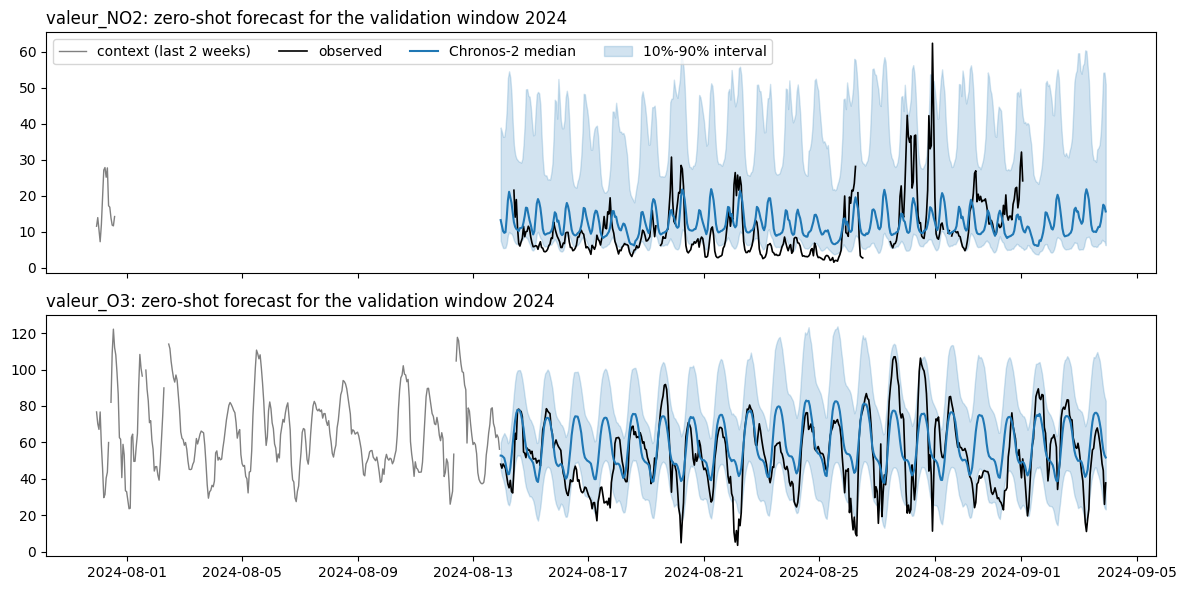

In [28]:
context, truth = folds["val_2024"]
q = quantile_preds["val_2024"]["Chronos-2 joint + calendar"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, p in zip(axes, ["valeur_NO2", "valeur_O3"]):
    ax.plot(context[p].iloc[-14 * 24:], color="grey", lw=1, label="context (last 2 weeks)")
    ax.plot(truth[p], color="black", lw=1.2, label="observed")
    ax.plot(truth.index, q[0.5][p], color="tab:blue", lw=1.5, label="Chronos-2 median")
    ax.fill_between(truth.index, q[0.1][p], q[0.9][p], color="tab:blue", alpha=0.2, label="10%-90% interval")
    ax.set_title(f"{p}: zero-shot forecast for the validation window 2024", loc="left")
axes[0].legend(ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

In [29]:
inside = (truth >= q[0.1].set_axis(truth.index)) & (truth <= q[0.9].set_axis(truth.index))
(100 * inside.sum() / truth.notna().sum()).round(1)       # % of observed hours inside the 10%-90% interval (80% expected)

valeur_NO2     61.9
valeur_CO      86.9
valeur_O3      87.1
valeur_PM10    82.9
valeur_PM25    74.1
dtype: float64

**Comments.**
- Chronos-2 beats every baseline: in `val_2024`, 5.57 (joint) and **5.38 with the calendar**, against 6.57 for the best baseline (−18%); in `sept_2023`, 9.24 against 9.93.
- The calendar covariates help on both windows, for almost every pollutant.
- **NO2:** with almost no recent NO2, the joint model still forecasts the low August level, probably by reading CO and O3. **O3:** the daily timing is right, but the median is smooth and misses the highest peaks.
- The 10–90% interval contains 83–87% of the observations for O3, CO and PM10, but only about 60% for NO2: the model is over-confident on NO2.
- **Weak spot:** in `sept_2023`, Chronos-2 is worse on NO2 than the plain mean of the history, because the September jump is not in its 11-month memory.

**Q20. Why can the median forecast be a good choice when the metric is MAE?**

- The value c that minimises the expected absolute error E|Y − c| is the **median** of Y (the mean minimises the squared error).
- Chronos-2 predicts quantiles directly, trained with the quantile loss, which for q = 0.5 is the absolute error.
- Pollution is skewed (NO2: mean 21.8, median 17.6): a mean forecast would be pulled up by rare episodes and overestimate ordinary hours.
- The price: the median is smooth and misses peaks. For pollution alerts, a high quantile such as 0.9 would be better.

## 5. Comparative experiments

Same windows, same metric: one forecast per pollutant against one joint forecast, then Chronos-2 against an LSTM trained on the data.

**Q21. Independent vs joint forecasting.** Chronos-2 run on each pollutant alone vs on the five together, without and with the calendar covariates.

In [30]:
def score_table():
    """MAE of every model run so far, on every validation window."""
    return pd.DataFrame({(fold, name): mae(folds[fold][1], p) for fold in folds for name, p in preds[fold].items()}).T

def show(models):
    """Rows of the score table for the given models, in this order, for each window."""
    return scores.loc[[(fold, m) for fold in folds for m in models]].round(3)

for fold, (context, truth) in folds.items():
    preds[fold]["Chronos-2 independent"] = chronos_forecast(context, joint=False)[0.5]
    preds[fold]["Chronos-2 independent + calendar"] = chronos_forecast(context, CALENDAR, joint=False)[0.5]
scores = score_table()
show(["Chronos-2 independent", "Chronos-2 joint", "Chronos-2 independent + calendar", "Chronos-2 joint + calendar"])

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  Chronos-2 independent                  7.714      0.048     12.916   
          Chronos-2 joint                        6.348      0.037     12.790   
          Chronos-2 independent + calendar       6.010      0.035     12.320   
          Chronos-2 joint + calendar             6.046      0.035     12.525   
sept_2023 Chronos-2 independent                 16.774      0.062     18.093   
          Chronos-2 joint                       16.415      0.061     18.267   
          Chronos-2 independent + calendar      15.952      0.058     20.414   
          Chronos-2 joint + calendar            15.997      0.058     18.846   

                                            valeur_PM10  valeur_PM25  average  
val_2024  Chronos-2 independent                   5.418        3.260    5.871  
          Chronos-2 joint                         5.292        3.374    5.568  
          Chronos-2 independent + calendar        5.405        3.350    5.424  
          Chronos-2 joint + calendar              4.991        3.319    5.383  
sept_2023 Chronos-2 independent                   6.782        5.095    9.361  
          Chronos-2 joint                         6.932        5.394    9.414  
          Chronos-2 independent + calendar        6.369        4.706    9.500  
          Chronos-2 joint + calendar              6.441        4.880    9.244

**Comments.**
- The joint model is better on average in three comparisons out of four, by 1% to 5%.
- The clear gain is on NO2 when its recent history is missing (`val_2024`, no covariates: 7.71 → 6.35): the joint model reads the situation from the other pollutants.
- With the calendar the gap shrinks, because the calendar gives the independent model the position in the daily and weekly cycle.
- Per pollutant, neither always wins (the independent model is often better on PM2.5). This matches the paper: multivariate gains are modest when the history is long. We keep **joint + calendar**, the best Chronos-2 variant on both windows.

**Q22. Foundation model vs neural network: a simple LSTM trained on the dataset.**

- **Input:** the last 2 weeks of the five pollutants (standardised on the context, missing values → mean), plus the hour and the weekday as sine and cosine.
- **Model:** one LSTM layer (64 units) whose last state feeds a linear layer that outputs the 504 × 5 values at once (multi-output strategy: no recursion, so no error accumulation).
- **Training:** every 2-week window of the context, 15 epochs of 100 batches, Adam, loss = MAE on the observed targets. One LSTM per window, trained on its context only (no leakage).

In [31]:
import torch.nn as nn

L = 336     # input window: the last 2 weeks

class LSTMForecaster(nn.Module):
    """Reads the last L hours (5 pollutants + calendar) and outputs the next H hours of the 5 pollutants at once."""
    def __init__(self, n_inputs, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_inputs, hidden, batch_first=True)
        self.head = nn.Linear(hidden, H * len(POLS))

    def forward(self, x):
        _, (h, _) = self.lstm(x)                          # h = last hidden state, a summary of the 2 weeks
        return self.head(h[-1]).view(-1, H, len(POLS))    # multi-output: the 504 x 5 values in one pass

def lstm_forecast(context, epochs=15, batch_size=64, seed=SEED):
    """Train an LSTM on the context only, then forecast the H hours after it."""
    torch.manual_seed(seed); np.random.seed(seed)
    mean, std = context.mean(), context.std()             # scaling fitted on the context only
    t = context.index
    cal = np.c_[np.sin(2 * np.pi * t.hour / 24), np.cos(2 * np.pi * t.hour / 24),
                np.sin(2 * np.pi * t.dayofweek / 7), np.cos(2 * np.pi * t.dayofweek / 7)]
    z = ((context - mean) / std).to_numpy(dtype="float32")          # targets, NaN kept
    X = np.c_[np.nan_to_num(z), cal].astype("float32")              # inputs, NaN -> 0 (= the mean)
    ends = np.arange(L, len(context) - H + 1)             # every forecast origin inside the context
    model = LSTMForecaster(X.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        for idx in np.random.permutation(ends)[:100 * batch_size].reshape(-1, batch_size):
            xb = torch.tensor(np.stack([X[i - L:i] for i in idx]), device=device)
            yb = torch.tensor(np.stack([z[i:i + H] for i in idx]), device=device)
            observed = ~torch.isnan(yb)
            loss = (model(xb) - torch.nan_to_num(yb)).abs()[observed].mean()     # MAE on the observed targets
            optimizer.zero_grad(); loss.backward(); optimizer.step()
    with torch.no_grad():
        out = model(torch.tensor(X[-L:][None], device=device))[0].cpu().numpy()
    return pd.DataFrame(out * std.to_numpy() + mean.to_numpy(), columns=POLS)

In [32]:
for fold, (context, truth) in folds.items():
    start = time.time()
    preds[fold]["LSTM"] = lstm_forecast(context)
    print(f"{fold:9s} | LSTM trained on the context and forecast in {time.time() - start:.0f} s")
scores = score_table()
show(["seasonal median 4 weeks", "Chronos-2 independent + calendar", "Chronos-2 joint + calendar", "LSTM"])

val_2024  | LSTM trained on the context and forecast in 70 s


sept_2023 | LSTM trained on the context and forecast in 67 s


valeur_NO2  valeur_CO  valeur_O3  \
val_2024  seasonal median 4 weeks                8.614      0.046     14.889   
          Chronos-2 independent + calendar       6.010      0.035     12.320   
          Chronos-2 joint + calendar             6.046      0.035     12.525   
          LSTM                                  10.840      0.036     12.263   
sept_2023 seasonal median 4 weeks               16.416      0.064     20.888   
          Chronos-2 independent + calendar      15.952      0.058     20.414   
          Chronos-2 joint + calendar            15.997      0.058     18.846   
          LSTM                                  13.499      0.057     19.107   

                                            valeur_PM10  valeur_PM25  average  
val_2024  seasonal median 4 weeks                 6.079        3.242    6.574  
          Chronos-2 independent + calendar        5.405        3.350    5.424  
          Chronos-2 joint + calendar              4.991        3.319    5.383  
          LSTM                                    5.074        3.792    6.401  
sept_2023 seasonal median 4 weeks                 7.037        5.259    9.933  
          Chronos-2 independent + calendar        6.369        4.706    9.500  
          Chronos-2 joint + calendar              6.441        4.880    9.244  
          LSTM                                    6.307        4.693    8.732

**Q23. Which approach works best: one model per pollutant, one joint model, or the LSTM? Explain the result using the MAE per pollutant.**

- **The joint Chronos-2 model is the most reliable:** the best in `val_2024` (5.38) and second in `sept_2023` (9.24), slightly ahead of one model per pollutant.
- **The LSTM is uneven, and NO2 explains it.** In `val_2024` its NO2 input is missing, so it forecasts an average Paris level, far above the quiet August (NO2 MAE ≈ 10.8 against 6.0). In `sept_2023`, this pull towards the typical level is exactly what the *rentrée* needs: it becomes the best model (≈ 8.7, NO2 ≈ 13.5 against 16.0). On O3, CO and PM it is competitive.
- The two models make **different errors**, which makes a blend a natural candidate (section 7).

## 6. Results and discussion

**Q24. Compare all models using the MAE per pollutant and the average MAE. Highlight cases where the average hides important differences.**

In [33]:
scores = score_table()
scores.round(3)

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  mean (competition baseline)           12.763      0.046     16.011   
          persistence                            7.429      0.046     16.160   
          seasonal naive 24 h                   10.374      0.045     14.254   
          seasonal naive 168 h                   9.469      0.044     17.303   
          seasonal median 4 weeks                8.614      0.046     14.889   
          Chronos-2 joint                        6.348      0.037     12.790   
          Chronos-2 joint + calendar             6.046      0.035     12.525   
          Chronos-2 independent                  7.714      0.048     12.916   
          Chronos-2 independent + calendar       6.010      0.035     12.320   
          LSTM                                  10.840      0.036     12.263   
sept_2023 mean (competition baseline)           14.881      0.059     23.529   
          persistence                           21.253      0.060     23.521   
          seasonal naive 24 h                   15.277      0.063     21.357   
          seasonal naive 168 h                  17.073      0.064     25.345   
          seasonal median 4 weeks               16.416      0.064     20.888   
          Chronos-2 joint                       16.415      0.061     18.267   
          Chronos-2 joint + calendar            15.997      0.058     18.846   
          Chronos-2 independent                 16.774      0.062     18.093   
          Chronos-2 independent + calendar      15.952      0.058     20.414   
          LSTM                                  13.499      0.057     19.107   

                                            valeur_PM10  valeur_PM25  average  
val_2024  mean (competition baseline)             6.141        4.442    7.881  
          persistence                             5.622        4.237    6.699  
          seasonal naive 24 h                     6.676        4.210    7.112  
          seasonal naive 168 h                    6.439        3.555    7.362  
          seasonal median 4 weeks                 6.079        3.242    6.574  
          Chronos-2 joint                         5.292        3.374    5.568  
          Chronos-2 joint + calendar              4.991        3.319    5.383  
          Chronos-2 independent                   5.418        3.260    5.871  
          Chronos-2 independent + calendar        5.405        3.350    5.424  
          LSTM                                    5.074        3.792    6.401  
sept_2023 mean (competition baseline)             7.429        5.172   10.214  
          persistence                             7.904        5.819   11.711  
          seasonal naive 24 h                     7.931        5.582   10.042  
          seasonal naive 168 h                    7.876        5.322   11.136  
          seasonal median 4 weeks                 7.037        5.259    9.933  
          Chronos-2 joint                         6.932        5.394    9.414  
          Chronos-2 joint + calendar              6.441        4.880    9.244  
          Chronos-2 independent                   6.782        5.095    9.361  
          Chronos-2 independent + calendar        6.369        4.706    9.500  
          LSTM                                    6.307        4.693    8.732

Next: each MAE divided by the seasonal naive's MAE (like the MASE): below 1 = better than the seasonal naive, and every pollutant weighs the same. Last table: the best model for each pollutant.

In [34]:
reference = scores.xs("seasonal naive 168 h", level=1)                    # MAE of the seasonal naive, per window
relative = pd.concat({fold: scores.loc[fold] / reference.loc[fold] for fold in folds})
relative["average"] = relative.drop(columns="average").mean(axis=1)       # every pollutant weighs the same here
display(relative.round(2))
pd.DataFrame({fold: scores.loc[fold].idxmin() for fold in folds})         # best model for each pollutant and on average

valeur_NO2  valeur_CO  valeur_O3  \
val_2024  mean (competition baseline)             1.35       1.03       0.93   
          persistence                             0.78       1.03       0.93   
          seasonal naive 24 h                     1.10       1.02       0.82   
          seasonal naive 168 h                    1.00       1.00       1.00   
          seasonal median 4 weeks                 0.91       1.03       0.86   
          Chronos-2 joint                         0.67       0.83       0.74   
          Chronos-2 joint + calendar              0.64       0.80       0.72   
          Chronos-2 independent                   0.81       1.08       0.75   
          Chronos-2 independent + calendar        0.63       0.79       0.71   
          LSTM                                    1.14       0.81       0.71   
sept_2023 mean (competition baseline)             0.87       0.92       0.93   
          persistence                             1.24       0.93       0.93   
          seasonal naive 24 h                     0.89       0.99       0.84   
          seasonal naive 168 h                    1.00       1.00       1.00   
          seasonal median 4 weeks                 0.96       1.00       0.82   
          Chronos-2 joint                         0.96       0.96       0.72   
          Chronos-2 joint + calendar              0.94       0.91       0.74   
          Chronos-2 independent                   0.98       0.97       0.71   
          Chronos-2 independent + calendar        0.93       0.90       0.81   
          LSTM                                    0.79       0.89       0.75   

                                            valeur_PM10  valeur_PM25  average  
val_2024  mean (competition baseline)              0.95         1.25     1.10  
          persistence                              0.87         1.19     0.96  
          seasonal naive 24 h                      1.04         1.18     1.03  
          seasonal naive 168 h                     1.00         1.00     1.00  
          seasonal median 4 weeks                  0.94         0.91     0.93  
          Chronos-2 joint                          0.82         0.95     0.80  
          Chronos-2 joint + calendar               0.78         0.93     0.77  
          Chronos-2 independent                    0.84         0.92     0.88  
          Chronos-2 independent + calendar         0.84         0.94     0.78  
          LSTM                                     0.79         1.07     0.90  
sept_2023 mean (competition baseline)              0.94         0.97     0.93  
          persistence                              1.00         1.09     1.04  
          seasonal naive 24 h                      1.01         1.05     0.96  
          seasonal naive 168 h                     1.00         1.00     1.00  
          seasonal median 4 weeks                  0.89         0.99     0.93  
          Chronos-2 joint                          0.88         1.01     0.91  
          Chronos-2 joint + calendar               0.82         0.92     0.86  
          Chronos-2 independent                    0.86         0.96     0.90  
          Chronos-2 independent + calendar         0.81         0.88     0.87  
          LSTM                                     0.80         0.88     0.82

,val_2024,sept_2023
valeur_NO2,Chronos-2 independent + calendar,LSTM
valeur_CO,Chronos-2 independent + calendar,LSTM
valeur_O3,LSTM,Chronos-2 independent
valeur_PM10,Chronos-2 joint + calendar,LSTM
valeur_PM25,seasonal median 4 weeks,LSTM
average,Chronos-2 joint + calendar,LSTM


**Comments.**
- Best on average: joint Chronos-2 + calendar in `val_2024` (0.77 of the seasonal naive's error), the LSTM in `sept_2023` (0.82). Every model beats every baseline on average.
- **The average hides that the best model changes with the pollutant.** In `val_2024`, the LSTM is the best on O3 but worse than the seasonal naive on NO2, and a simple baseline (the 4-week median) is the best on PM2.5.
- CO weighs nothing in the raw average: an error on CO only shows in the relative table.

**Q25. Does performance change between the beginning and the end of the 504-hour horizon?** Average MAE of the five pollutants by week (table) and by day (plot).

week 1  week 2  week 3
val_2024  persistence                   6.33    6.97    6.81
          seasonal naive 168 h          6.81    7.23    7.94
          Chronos-2 joint + calendar    4.81    4.96    6.40
          LSTM                          6.52    6.17    6.35
sept_2023 persistence                  19.09   11.05    6.02
          seasonal naive 168 h         16.83   10.65    6.57
          Chronos-2 joint + calendar   15.16    8.45    4.96
          LSTM                         13.86    6.77    5.88

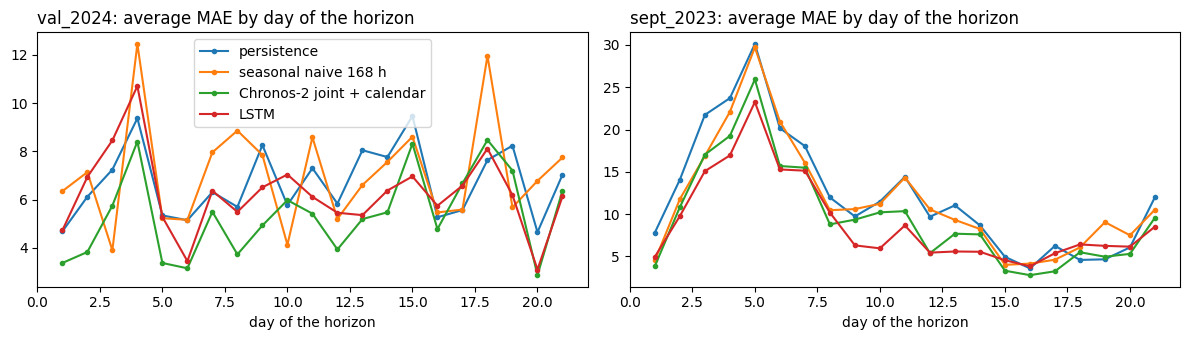

In [35]:
def mae_by_step(truth, pred, step):
    """Average MAE over the 5 pollutants, for each block of `step` hours of the horizon."""
    errors = (truth - pred.set_axis(truth.index).clip(lower=0)).abs()
    return errors.groupby(np.arange(H) // step + 1).mean().mean(axis=1)

shown = ["persistence", "seasonal naive 168 h", "Chronos-2 joint + calendar", "LSTM"]
weekly = pd.DataFrame({(fold, name): mae_by_step(folds[fold][1], preds[fold][name], 168) for fold in folds for name in shown}).T
display(weekly.rename(columns=lambda w: f"week {w}").round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, fold in zip(axes, folds):
    for name in shown:
        mae_by_step(folds[fold][1], preds[fold][name], 24).plot(ax=ax, marker=".", label=name)
    ax.set_title(f"{fold}: average MAE by day of the horizon", loc="left")
    ax.set_xlabel("day of the horizon")
axes[0].legend()
plt.tight_layout(); plt.show()

**Comments.**
- The error does **not** simply grow with the horizon: after a few days, every model forecasts a typical cycle, and the error depends on what happens each week.
- `val_2024`: Chronos-2 is very good in weeks 1–2 and degrades in week 3, when NO2 rises at the end of the holidays; the LSTM stays flat.
- `sept_2023`: the error *decreases*, because week 1 contains the heat wave and the *rentrée* jump (day 5 is the worst day for every model).

**Q26. Plot observed vs predicted values. Comment on one clear success or failure.**

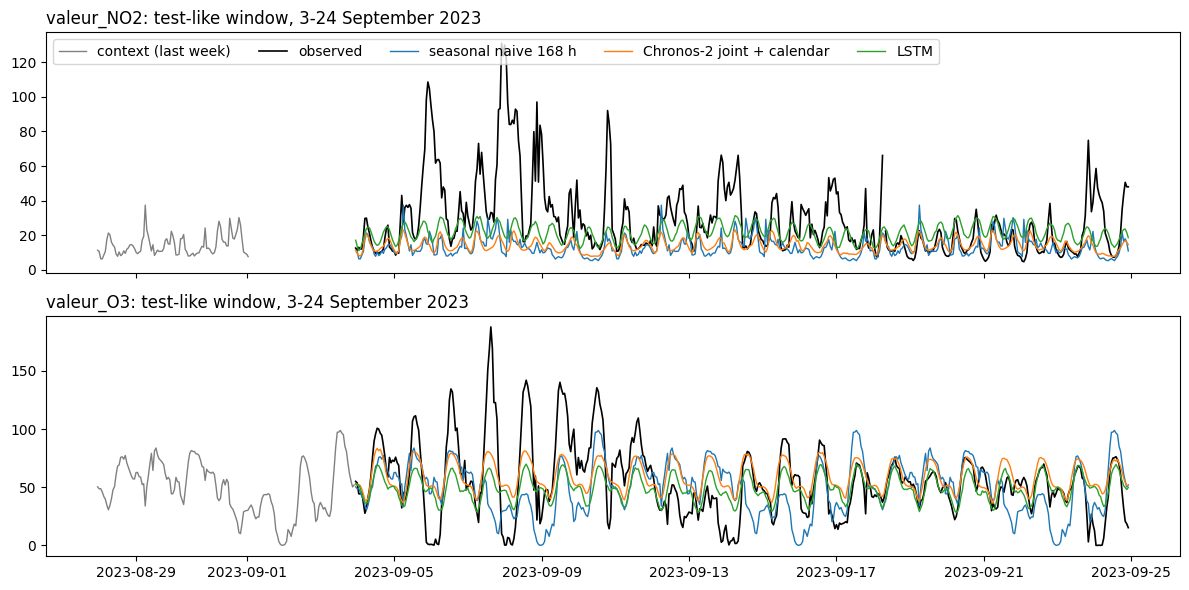

In [36]:
context, truth = folds["sept_2023"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, p in zip(axes, ["valeur_NO2", "valeur_O3"]):
    ax.plot(context[p].iloc[-7 * 24:], color="grey", lw=1, label="context (last week)")
    ax.plot(truth[p], color="black", lw=1.2, label="observed")
    for name in ["seasonal naive 168 h", "Chronos-2 joint + calendar", "LSTM"]:
        ax.plot(truth.index, preds["sept_2023"][name][p].clip(lower=0), lw=1, label=name)
    ax.set_title(f"{p}: test-like window, 3-24 September 2023", loc="left")
axes[0].legend(ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

**Comments.**
- **Clear failure (NO2):** from 5 September, NO2 jumps to 40–130 µg/m³ (end of the holidays plus the heat wave), while every model stays at the summer level of its context (10–30).
- **Success (O3, second half):** once the episode is over, Chronos-2 and the LSTM follow the O3 daily cycle with the right timing and amplitude. The seasonal naive does worse: it copies the deep night dips of the heat-wave week.

**Q27. Which model performs best overall? Is it also best for every pollutant?**

- **Overall, it depends on the window:** joint Chronos-2 + calendar in `val_2024`, the LSTM in `sept_2023`, and over both windows the blend selected in section 7.
- **Not for every pollutant:** the best model changes with the pollutant (Q24), because each has its own drivers (traffic for NO2, sunshine for O3, episodes for particles).

**Q28. Where does the foundation model fail compared with the seasonal naive baseline?** Comparison on the 10% highest and lowest hours, and spread of the forecasts vs the observations.

In [37]:
rows = {}
for fold, (context, truth) in folds.items():
    peak, low = truth > truth.quantile(0.9), truth < truth.quantile(0.1)     # 10% highest and 10% lowest hours
    for name in ["seasonal naive 168 h", "Chronos-2 joint + calendar"]:
        pred = preds[fold][name].set_axis(truth.index).clip(lower=0)
        errors = (truth - pred).abs()
        rows[(fold, name, "MAE on peak hours")] = errors[peak].mean()
        rows[(fold, name, "MAE on low hours")] = errors[low].mean()
        rows[(fold, name, "std forecast / std observed")] = pred.std() / truth.std()
pd.DataFrame(rows).T.round(2)

valeur_NO2  \
val_2024  seasonal naive 168 h       MAE on peak hours                 12.11   
                                     MAE on low hours                  11.05   
                                     std forecast / std observed        1.39   
          Chronos-2 joint + calendar MAE on peak hours                 14.18   
                                     MAE on low hours                   6.64   
                                     std forecast / std observed        0.42   
sept_2023 seasonal naive 168 h       MAE on peak hours                 62.89   
                                     MAE on low hours                   3.86   
                                     std forecast / std observed        0.26   
          Chronos-2 joint + calendar MAE on peak hours                 63.21   
                                     MAE on low hours                   3.61   
                                     std forecast / std observed        0.17   

                                                                  valeur_CO  \
val_2024  seasonal naive 168 h       MAE on peak hours                 0.12   
                                     MAE on low hours                  0.04   
                                     std forecast / std observed       0.66   
          Chronos-2 joint + calendar MAE on peak hours                 0.12   
                                     MAE on low hours                  0.02   
                                     std forecast / std observed       0.26   
sept_2023 seasonal naive 168 h       MAE on peak hours                 0.26   
                                     MAE on low hours                  0.03   
                                     std forecast / std observed       0.41   
          Chronos-2 joint + calendar MAE on peak hours                 0.28   
                                     MAE on low hours                  0.04   
                                     std forecast / std observed       0.14   

                                                                  valeur_O3  \
val_2024  seasonal naive 168 h       MAE on peak hours                18.24   
                                     MAE on low hours                 34.12   
                                     std forecast / std observed       0.94   
          Chronos-2 joint + calendar MAE on peak hours                14.19   
                                     MAE on low hours                 28.35   
                                     std forecast / std observed       0.63   
sept_2023 seasonal naive 168 h       MAE on peak hours                56.88   
                                     MAE on low hours                 36.40   
                                     std forecast / std observed       0.72   
          Chronos-2 joint + calendar MAE on peak hours                45.39   
                                     MAE on low hours                 42.62   
                                     std forecast / std observed       0.39   

                                                                  valeur_PM10  \
val_2024  seasonal naive 168 h       MAE on peak hours                  12.01   
                                     MAE on low hours                    8.36   
                                     std forecast / std observed         1.25   
          Chronos-2 joint + calendar MAE on peak hours                  13.14   
                                     MAE on low hours                    8.51   
                                     std forecast / std observed         0.36   
sept_2023 seasonal naive 168 h       MAE on peak hours                  23.33   
                                     MAE on low hours                    9.04   
                                     std forecast / std observed         0.76   
          Chronos-2 joint + calendar MAE on peak hours                  24.20   
                                     MAE on low hours                    6.77 

- On the average MAE, Chronos-2 beats the seasonal naive on every pollutant of both windows.
- **It fails on peaks:** its median is far too smooth (NO2 spread ≈ 40% of the observed one), so on the highest hours it is worse than the seasonal naive for NO2 and PM10. The seasonal naive keeps a realistic amplitude, even when its peaks are mistimed.
- **And on unusual dips:** in `sept_2023`, it is worse on the lowest O3 hours.
- So Chronos-2 is better on *typical* hours, while the seasonal naive keeps the *amplitude*. For alerts, where peaks matter, this is a real weakness.

**Q29. List three limitations of this work: one about the data, one about the evaluation and one about the model.**

- **Data:** many gaps (NO2 missing just before the test) and no weather or traffic data, which drive the episodes. Part of the test truth was imputed by the organisers.
- **Evaluation:** only two 3-week windows, and the covariates and blend weight were chosen on them, so the scores are noisy and slightly optimistic. A rolling evaluation over many origins would be more reliable.
- **Model:** Chronos-2 only sees the last 11 months, so it cannot know that NO2 jumps every September. Its median is smooth and its NO2 intervals are too narrow. The LSTM is small, untuned and depends on the random seed.

## 7. Final forecast and submission

**Q30. Select the final method using validation results only, then forecast the test period.** Rule fixed in section 2: the lowest average MAE over the two windows, among Chronos-2, the LSTM and two blends of both.

In [38]:
for fold in folds:
    for w in (0.7, 0.5):
        preds[fold][f"blend {w:.0%} Chronos-2 + {1 - w:.0%} LSTM"] = w * preds[fold]["Chronos-2 joint + calendar"] + (1 - w) * preds[fold]["LSTM"]
scores = score_table()
candidates = {"Chronos-2 joint + calendar": 1.0, "blend 70% Chronos-2 + 30% LSTM": 0.7,
              "blend 50% Chronos-2 + 50% LSTM": 0.5, "LSTM": 0.0}        # model: weight of Chronos-2
selection = scores["average"].unstack(level=0).loc[list(candidates), list(folds)]
selection["mean of the 2 windows"] = selection.mean(axis=1)
best = selection["mean of the 2 windows"].idxmin()
print("selected method:", best)
display(selection.round(3))
show(list(candidates))

selected method: blend 70% Chronos-2 + 30% LSTM


,val_2024,sept_2023,mean of the 2 windows
Chronos-2 joint + calendar,5.383,9.244,7.314
blend 70% Chronos-2 + 30% LSTM,5.618,8.850,7.234
blend 50% Chronos-2 + 50% LSTM,5.810,8.701,7.255
LSTM,6.401,8.732,7.567


valeur_NO2  valeur_CO  valeur_O3  \
val_2024  Chronos-2 joint + calendar           6.046      0.035     12.525   
          blend 70% Chronos-2 + 30% LSTM       7.297      0.034     12.349   
          blend 50% Chronos-2 + 50% LSTM       8.225      0.034     12.282   
          LSTM                                10.840      0.036     12.263   
sept_2023 Chronos-2 joint + calendar          15.997      0.058     18.846   
          blend 70% Chronos-2 + 30% LSTM      14.834      0.058     18.461   
          blend 50% Chronos-2 + 50% LSTM      14.236      0.057     18.430   
          LSTM                                13.499      0.057     19.107   

                                          valeur_PM10  valeur_PM25  average  
val_2024  Chronos-2 joint + calendar            4.991        3.319    5.383  
          blend 70% Chronos-2 + 30% LSTM        4.978        3.433    5.618  
          blend 50% Chronos-2 + 50% LSTM        4.987        3.523    5.810  
          LSTM                                  5.074        3.792    6.401  
sept_2023 Chronos-2 joint + calendar            6.441        4.880    9.244  
          blend 70% Chronos-2 + 30% LSTM        6.183        4.716    8.850  
          blend 50% Chronos-2 + 50% LSTM        6.132        4.648    8.701  
          LSTM                                  6.307        4.693    8.732

**Comments.**
- The selected method is printed above. In our run it is **70% Chronos-2 + 30% LSTM** (7.23 against 7.31 for Chronos-2 alone).
- The blend works because the two models make opposite errors: it loses a little in August 2024 and gains more in September 2023, the situation of the test.
- The top candidates are within about 1%, and they are compared on the windows that select them, so the selected score is slightly optimistic.
- For the test, Chronos-2 reads the whole history (with the NO2 gap) and the calendar of September 2024; the LSTM is retrained on all the training data.

blend 70% Chronos-2 + 30% LSTM: test forecast ready in 90 s | shape (504, 5)


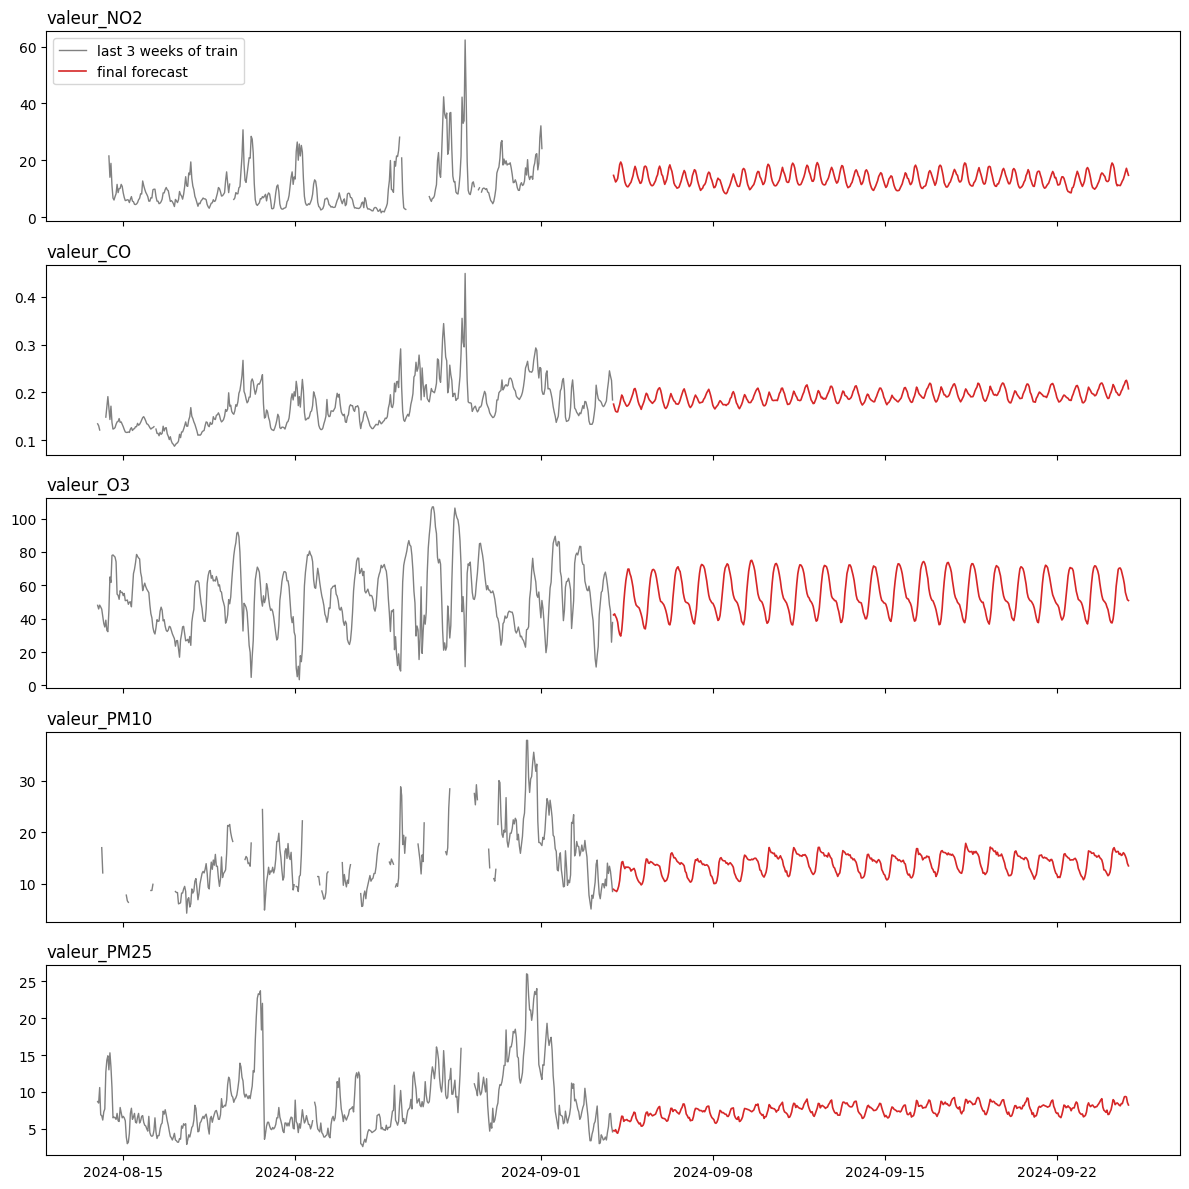

In [39]:
w = candidates[best]                               # weight of Chronos-2 in the final forecast
context = df                                       # all the data before the test: 2020-01-01 -> 2024-09-03 22h
assert context.index[-1] + pd.Timedelta("1h") == test["timestamp"].iloc[0]
start = time.time()
chronos_test = chronos_forecast(context, CALENDAR)[0.5]
lstm_test = lstm_forecast(context)                 # LSTM retrained on all the training data
final = (w * chronos_test + (1 - w) * lstm_test).clip(lower=0)
print(f"{best}: test forecast ready in {time.time() - start:.0f} s | shape {final.shape}")

fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for ax, p in zip(axes, POLS):
    ax.plot(df[p].iloc[-21 * 24:], color="grey", lw=1, label="last 3 weeks of train")
    ax.plot(test["timestamp"], final[p], color="tab:red", lw=1.2, label="final forecast")
    ax.set_title(p, loc="left")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

**Q31. Check that the final submission follows the required format and contains complete, correctly ordered predictions for all five pollutants.**

In [40]:
submission = sample.copy()
submission[POLS] = final[POLS].to_numpy()
assert list(submission.columns) == list(sample.columns)             # same columns, same order as the sample
assert submission["id"].equals(test["id"])                           # same ids, same order as test.csv
assert len(submission) == H and submission[POLS].notna().all().all() and (submission[POLS] >= 0).all().all()
submission.to_csv("submission.csv", index=False)
print("submission.csv saved:", submission.shape, "| from", submission["id"].iloc[0], "to", submission["id"].iloc[-1])
submission[POLS].describe().loc[["mean", "min", "max"]].round(2)

submission.csv saved: (504, 6) | from 2024-09-03 23 to 2024-09-24 22


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
mean,13.51,0.19,54.62,13.89,7.58
min,8.21,0.16,29.57,8.49,4.41
max,19.36,0.23,74.98,17.84,9.39


- All checks pass: same columns and `id` order as the sample, 504 rows, no missing or negative value. The file is saved as `submission.csv`.
- The forecast stays at late-August levels (NO2 mean ≈ 13.5), probably too low for September (NO2 was 23–29 µg/m³ in previous Septembers). This is the weakness seen in `sept_2023`; we did not correct it by hand, because such a correction could not be validated.

## References

- A. F. Ansari et al. (2025). *Chronos-2: From Univariate to Universal Forecasting*. arXiv:2510.15821. Code and quick-start: github.com/amazon-science/chronos-forecasting; model `amazon/chronos-2` on Hugging Face.
- French public holidays: Python package `holidays` (pypi.org/project/holidays).
- Paris school holidays (zone C): French Ministry of Education open data, dataset *Calendrier scolaire* (`fr-en-calendrier-scolaire`), data.education.gouv.fr.
- Kaggle competition `x-hec-ts-2025-predicting-air-quality-in-paris`: description of the data (units, CET timestamps).
- Course slides *Time Series – Interactive Course* (modules 1.6 to 1.8, 2.2 and 2.4).